# Week 6 · 05 CNNs in PyTorch, one layer at a time

`04`'s layers, put together into a convolutional network (CNN) for MNIST. You asked for smaller stepping stones in PyTorch, so §2 builds the network **one layer at a time**: pass a batch through, print its shape, check it against `04`'s formula, add the next layer. Only then is it wrapped into a model and trained (§4). §5 reads the classic architectures, including the ResNet block, line by line. MNIST was downloaded in Week 5; nothing is downloaded again.

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

## Words you'll see
- **CNN**: convolutional neural network: convolution and pooling layers that find patterns, followed by dense layers that classify.
- **(N, C, H, W)**: the shape of an image batch in PyTorch: N images, C channels, height H, width W.
- **flatten**: turning each image's (C, H, W) block of numbers into one long row of C·H·W numbers, so that a dense layer can read it.
- **architecture**: the list of layers a network is built from, and how they connect.

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from figures import *
import checks; checks.load(globals(), "05")      # defines check(n)

## M. The map: what's in this notebook and why

🖼 **Picture.** The network of this notebook, with the shape after each layer: two blocks of (convolution → ReLU → max pool), then flatten and one dense layer to the 10 digit scores.

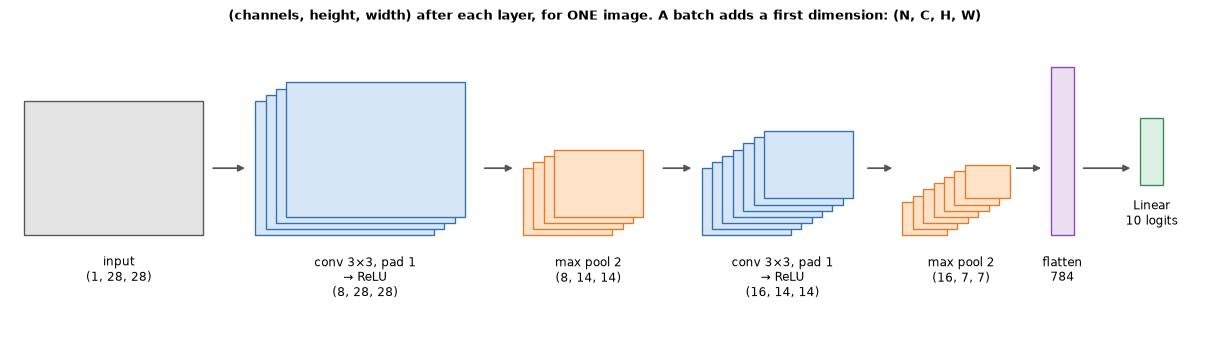

In [2]:
fig_cnn_shapes()

| Section | What | Why it's here |
|---|---|---|
| 0 | recap, and booklet 15's training loop from memory | the loop that trains the CNN in §4 |
| E | a trained CNN reads a test digit | start from the end: what it stores and what it does |
| 1 | image batches: (N, C, H, W) | the one shape convention to remember |
| 2 | building the CNN one layer at a time | check every shape before training anything |
| 3 | counting its parameters | the exam question, and why the CNN is 11 times smaller than the MLP |
| 4 | training it | the same five lines as always |
| 5 | classic architectures, and reading a ResNet block | LeNet, VGG, ResNet: the ideas, and code reading |
| 6 | exercises | the block's hand-written parts |

## 0. Recap first · 10 min, closed book

**Quick check:** Output size of a 3×3 convolution with padding 1, stride 1, on 28×28?

<details><summary>Answer</summary>

$\lfloor (28 + 2 - 3)/1 \rfloor + 1 = 28$: "same" padding. [04 §3 ↗](04_convolution.ipynb)

</details>

**Quick check:** `nn.Conv2d(8, 16, 3)`: weight shape and number of parameters?

<details><summary>Answer</summary>

`(16, 8, 3, 3)`; $16 \cdot 8 \cdot 9 + 16 = 1168$. [04 §4 ↗](04_convolution.ipynb)

</details>

**Quick check:** What does a 2×2 max pool do to a (8, 28, 28) feature map?

<details><summary>Answer</summary>

(8, 14, 14): same channels, half the height and width. [04 §5 ↗](04_convolution.ipynb)

</details>

**Quick check:** Why must the model output logits, not probabilities, when the loss is `nn.CrossEntropyLoss`?

<details><summary>Answer</summary>

The loss applies softmax itself; a softmax in the model would be applied twice. [Week 5 · 06 §4 ↗](../week5/06_pytorch_basics.ipynb)

</details>

**Quick check:** `model.train()` before the training loop and `model.eval()` before testing: why, for a model with batch norm?

<details><summary>Answer</summary>

Batch norm uses the batch's statistics while training and the stored running averages while testing. [03 §2 ↗](03_training_stability.ipynb)

</details>

**Exercise 1 · Booklet 15: one epoch of the training loop.** Call `model.train()`, then for every batch the five lines: guess (`model(xb)`), score (`loss_fn`), wipe (`opt.zero_grad()`), blame (`loss.backward()`), adjust (`opt.step()`). Return the mean loss per sample: add `loss.item() * len(xb)` for every batch, divide by `len(loader.dataset)`.

**Example**: what goes in, and what should come out:
```python
# used in §4 to train the CNN:
train_epoch(model, train_loader, nn.CrossEntropyLoss(), opt)    # → about 0.49 for the first epoch from random weights
```

In [3]:
def train_epoch(model, loader, loss_fn, opt):
    pass  # your code

In [4]:
check(1)

Exercise 1: something returned None. Not written yet, or a missing `return`?


## E. Start from the end: a trained CNN reads a test digit

`mnist_cnn.pt` in this folder is the network of §M, trained for two epochs on the 60,000 MNIST training images by the code in §4. What it stores:

In [5]:
model = nn.Sequential(nn.Conv2d(1, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                      nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                      nn.Flatten(), nn.Linear(16 * 7 * 7, 10))      # the same layers it was saved with
model.load_state_dict(torch.load("mnist_cnn.pt"))
model.eval()
for name, t in model.state_dict().items():
    print(name, tuple(t.shape))
print(sum(p.numel() for p in model.parameters()))
# → 0.weight (8, 1, 3, 3)
#   0.bias (8,)
#   3.weight (16, 8, 3, 3)
#   3.bias (16,)
#   7.weight (10, 784)
#   7.bias (10,)
#   9098

0.weight (8, 1, 3, 3)
0.bias (8,)
3.weight (16, 8, 3, 3)
3.bias (16,)
7.weight (10, 784)
7.bias (10,)
9098


| Stored | Shape | What it is |
|---|---|---|
| `0.weight`, `0.bias` | (8, 1, 3, 3), (8,) | layer 0: eight 3×3 kernels on the 1-channel image (80 numbers) |
| `3.weight`, `3.bias` | (16, 8, 3, 3), (16,) | layer 3: sixteen kernels, each 8 channels deep (1168 numbers) |
| `7.weight`, `7.bias` | (10, 784), (10,) | the dense layer: 784 flattened values → 10 digit scores (7850 numbers) |

Layers 1, 2, 4, 5 and 6 (ReLU, pool, flatten) store nothing; that's why the names jump from 0 to 3 to 7. **A new image** from the test set:

In [6]:
train_set, test_set = mnist_sets()                     # from figures.py: MNIST from week5/data
img, label = test_set[0]                               # img: (1, 28, 28) float in [0, 1]; label: an int
with torch.no_grad():
    probs = torch.softmax(model(img[None]), dim=1)     # img[None]: a batch of ONE, (1, 1, 28, 28)
print(label, probs.argmax().item(), round(probs.max().item(), 3))   # → 7 7 1.0

7 7 1.0


🖼 **Picture.** The test image and the CNN's probabilities.

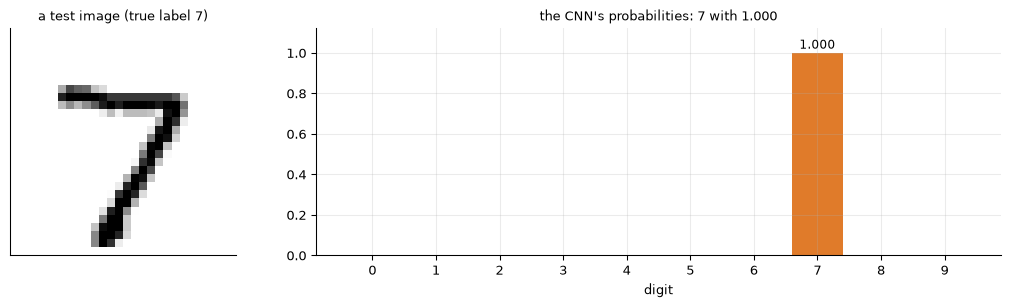

In [7]:
fig_cnn_prediction()

🖼 **Picture.** What the network learned in its first layer: 8 kernels (top) and the 8 feature maps each makes from a training image (bottom). Several look like the edge detectors of `04`, in different directions; nobody told the network to make them.

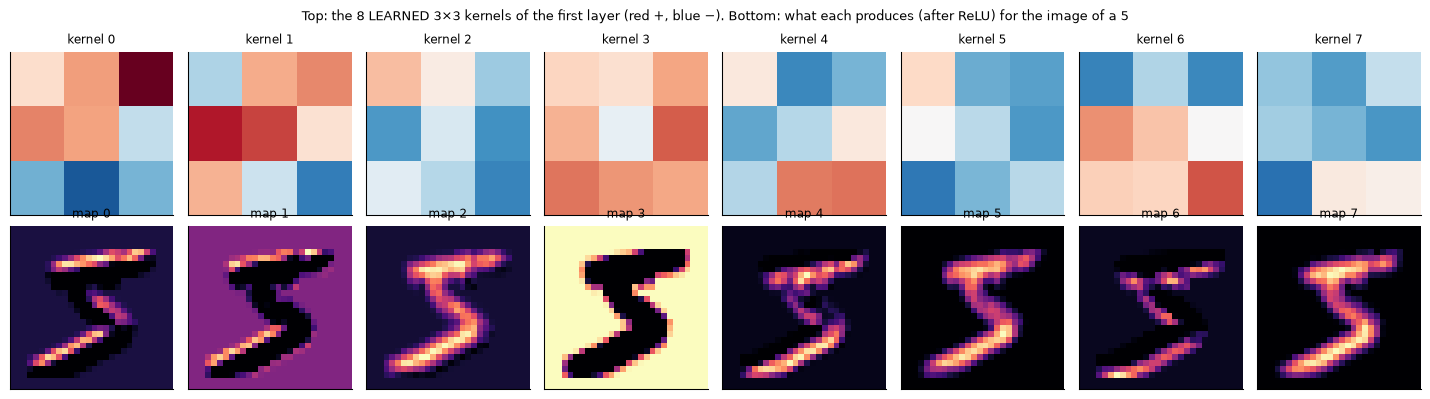

In [8]:
fig_cnn_filters()

**The rest of this notebook answers:** what shapes flow through these layers (§1–2), how 9098 parameters are enough when the Week 5 MLP for MNIST had 101,770 (§3), and what code produced the file (§4).

## 1. Image batches: (N, C, H, W)

Every image tensor in PyTorch has four dimensions, always in this order:

| Dimension | Letter | MNIST batch from a `DataLoader` | Meaning |
|---|---|---|---|
| 0 | N | 128 | which image in the batch |
| 1 | C | 1 | which channel (1 for grey, 3 for colour; later: which feature map) |
| 2 | H | 28 | which row of pixels |
| 3 | W | 28 | which column |

In [9]:
loader = DataLoader(train_set, batch_size=128, shuffle=True)
xb, yb = next(iter(loader))            # one batch
print(xb.shape, yb.shape, xb.dtype)     # → torch.Size([128, 1, 28, 28]) torch.Size([128]) torch.float32

torch.Size([128, 1, 28, 28]) torch.Size([128]) torch.float32


**A single image** is `(1, 28, 28)`, which a layer won't accept on its own: add the batch dimension with `img[None]` (or `img.unsqueeze(0)`) to get `(1, 1, 28, 28)`, a batch of one. You did the same with `x[None]` in Week 5.

## 2. Building the CNN one layer at a time

The stepping-stone way to build any network: take a small batch, apply **one** layer, print the shape, check it against what you expect, then add the next. Shape errors show up immediately, one layer at a time, instead of as a confusing error at the end. Two images are enough:

In [10]:
x = xb[:2]                              # (2, 1, 28, 28): 2 images
print(x.shape)                          # → torch.Size([2, 1, 28, 28])

torch.Size([2, 1, 28, 28])


**Layer 1: convolution.** 8 kernels of 3×3, padding 1. Expect: channels $1 \to 8$; size $\lfloor (28 + 2 - 3)/1 \rfloor + 1 = 28$, unchanged ("same" padding).

In [11]:
conv1 = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1)
h = conv1(x)
print(h.shape)                          # → torch.Size([2, 8, 28, 28])

torch.Size([2, 8, 28, 28])


**Layer 2: ReLU**, entry by entry: the shape can't change. **Layer 3: max pool 2**: channels stay 8, height and width halve to 14.

In [12]:
h = torch.relu(h)
h = nn.MaxPool2d(2)(h)
print(h.shape)                          # → torch.Size([2, 8, 14, 14])

torch.Size([2, 8, 14, 14])


**Layers 4–6: the second block.** The next convolution must take **8** input channels (what the previous layer made) and makes 16. Same padding keeps 14×14; the pool halves it to 7×7.

In [13]:
conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1)
h = nn.MaxPool2d(2)(torch.relu(conv2(h)))
print(h.shape)                          # → torch.Size([2, 16, 7, 7])

torch.Size([2, 16, 7, 7])


**Layer 7: flatten.** A dense layer needs one row per image. `nn.Flatten()` keeps dimension 0 (the images) and joins the rest: $16 \times 7 \times 7 = 784$ numbers per image.

In [14]:
h = nn.Flatten()(h)
print(h.shape)                          # → torch.Size([2, 784])

torch.Size([2, 784])


**Layer 8: the dense layer** to 10 logits, one per digit. Its `in_features` must be the 784 we just computed; getting this number wrong is the most common CNN bug (`06` III2). That's why we printed it.

In [15]:
fc = nn.Linear(16 * 7 * 7, 10)
print(fc(h).shape)                      # → torch.Size([2, 10])

torch.Size([2, 10])


**Now wrap it up**, in either of the two ways from Week 5 · 06. As an `nn.Sequential`, exactly as in §E. Or as a class, where `forward` repeats the steps we just did:

In [16]:
class SmallCNNClass(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)             # one pool object, used twice: it has no weights
        self.fc = nn.Linear(16 * 7 * 7, 10)

    def forward(self, x):                       # x: (N, 1, 28, 28)
        x = self.pool(torch.relu(self.conv1(x)))    # (N, 8, 14, 14)
        x = self.pool(torch.relu(self.conv2(x)))    # (N, 16, 7, 7)
        return self.fc(x.flatten(start_dim=1))      # (N, 784) -> (N, 10): flatten everything after dim 0

print(SmallCNNClass()(x).shape)                 # → torch.Size([2, 10])

torch.Size([2, 10])


**In one sentence:** build a network by applying one layer at a time to a small batch and checking each shape against the size formula; then wrap the layers in `nn.Sequential` or an `nn.Module` class.

## 3. Counting its parameters

| Layer | Calculation | Parameters |
|---|---|---|
| `Conv2d(1, 8, 3)` | 8 · 1 · 3 · 3 + 8 | 80 |
| `Conv2d(8, 16, 3)` | 16 · 8 · 3 · 3 + 16 | 1,168 |
| `Linear(784, 10)` | 784 · 10 + 10 | 7,850 |
| ReLU, MaxPool, Flatten | nothing to learn | 0 |
| total |  | **9,098** |

**Compare:** Week 5's MLP for MNIST, $784 \to 128 \to 10$, has $784 \cdot 128 + 128 + 128 \cdot 10 + 10 = 101{,}770$ parameters, 11 times more, and with the same training (two epochs, Adam) it reaches 0.950 against this CNN's 0.972. The convolutions get their power from **sharing** a few weights across all positions, not from having many weights. Most of the CNN's parameters are in its last, dense layer.

## 4. Training it

Nothing new: the same five lines as every model since Week 5. Two epochs over the 60,000 training images, then the test accuracy once at the end. On the CPU this takes about 10 seconds (it's this exact code that made `mnist_cnn.pt`, so the numbers match §E).

In [17]:
torch.manual_seed(0)
cnn = nn.Sequential(nn.Conv2d(1, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Flatten(), nn.Linear(16 * 7 * 7, 10))
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
for epoch in range(2):
    cnn.train()
    for xb, yb in train_loader:                 # 469 batches per epoch
        loss = loss_fn(cnn(xb), yb)              # 1 guess, 2 score
        opt.zero_grad(); loss.backward(); opt.step()   # 3 wipe, 4 blame, 5 adjust

cnn.eval(); correct = 0
with torch.no_grad():
    for xb, yb in DataLoader(test_set, batch_size=1000):
        correct += (cnn(xb).argmax(dim=1) == yb).sum().item()
print(correct / len(test_set))                  # → 0.9717

0.9717


**Why the test accuracy is computed only at the end:** creating a `DataLoader` iterator draws a random number from PyTorch's generator, even without shuffling, so testing between epochs would change the next epoch's shuffle and the final weights would differ from `mnist_cnn.pt`. A small detail; it only matters when you want exactly reproducible numbers.

**Colour images (CIFAR-10, optional, at home).** For 32×32 colour photos only the first layer and the flatten size change: `nn.Conv2d(3, 32, 3, padding=1)` (3 input channels), and after two 2×2 pools the maps are 8×8, so the dense layer takes $C \cdot 8 \cdot 8$ inputs. Load it with `datasets.CIFAR10(root="data", download=True, transform=transforms.ToTensor())` (170 MB). Add augmentation (`transforms.RandomHorizontalFlip()`, `02` §5) and batch norm (`03` §2); expect about 0.70 after a few epochs with a network this small.

## 5. Classic architectures, and reading a ResNet block

Three famous designs, each one idea on top of the last:

| Network (year) | The idea | What it looks like |
|---|---|---|
| LeNet-5 (1998) | convolution + pooling to find features, dense layers to classify | conv → pool → conv → pool → dense → dense; our SmallCNN is a LeNet |
| VGG (2014) | go deep with only small 3×3 kernels (`04` §6); double the channels after every pool | blocks of 2–3 convolutions (3×3, same padding) then a pool; 64 → 128 → 256 → 512 channels |
| ResNet (2015) | residual blocks (`03` §4) so that 50–150 layers still train | blocks of conv → BN → ReLU → conv → BN, plus the skip connection |

**Reading code: a ResNet basic block**, simplified from torchvision's `BasicBlock`. Read it the way the exam asks: list the layers, then follow one input's shape through `forward`.

In [18]:
class BasicBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, kernel_size=3, stride=stride, padding=1, bias=False)  # no bias: BN shifts
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.down = None
        if stride != 1 or c_in != c_out:              # the skip path must match the new shape
            self.down = nn.Sequential(nn.Conv2d(c_in, c_out, kernel_size=1, stride=stride, bias=False),
                                      nn.BatchNorm2d(c_out))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))     # conv -> BN -> ReLU
        out = self.bn2(self.conv2(out))               # conv -> BN (no ReLU yet)
        skip = x if self.down is None else self.down(x)
        return torch.relu(out + skip)                 # add the input back, THEN ReLU

block = BasicBlock(16, 32, stride=2)
print(block(torch.randn(2, 16, 14, 14)).shape, sum(p.numel() for p in block.parameters()))
# → torch.Size([2, 32, 7, 7]) 14528

torch.Size([2, 32, 7, 7]) 14528


**Following the shape** for an input `(2, 16, 14, 14)`: `conv1` has stride 2, so $\lfloor (14 + 2 - 3)/2 \rfloor + 1 = 7$ and 32 channels: `(2, 32, 7, 7)`. `conv2` keeps it (stride 1, same padding). The input itself is still `(2, 16, 14, 14)`, which can't be added to `(2, 32, 7, 7)`, so `down` is used: a **1×1 convolution** with stride 2 (it changes the channel count, 16 → 32, and skips every other pixel) plus batch norm. Now both are `(2, 32, 7, 7)` and can be added.

**Counting its parameters:** conv1 $32 \cdot 16 \cdot 9 = 4608$; bn1 $2 \cdot 32 = 64$ ($\gamma$ and $\beta$ per channel); conv2 $32 \cdot 32 \cdot 9 = 9216$; bn2 64; the 1×1 conv $32 \cdot 16 = 512$; its BN 64. Total $14{,}528$.

## 6. Exercises

**Exercise 2 · The CNN as a class.** `SmallCNN()`, a subclass of `nn.Module`, with the layers of §2 created **in this order**: `self.conv1 = nn.Conv2d(1, 8, 3, padding=1)`, `self.conv2 = nn.Conv2d(8, 16, 3, padding=1)`, a pool, `self.fc = nn.Linear(784, 10)`. `forward(x)` for `x` `(N, 1, 28, 28)` returns the logits `(N, 10)`.

**Example**: what goes in, and what should come out:
```python
SmallCNN()(torch.zeros(3, 1, 28, 28)).shape    # → torch.Size([3, 10])
sum(p.numel() for p in SmallCNN().parameters())   # → 9098
```

In [19]:
class SmallCNN(nn.Module):
    def __init__(self):
        pass  # your code

    def forward(self, x):
        pass  # your code

In [20]:
check(2)

Exercise 2: a method or attribute is missing: 'SmallCNN' object has no attribute '_parameters'. Check the spelling, `self.`, and super().__init__()


**Exercise 3 · Shape after every layer.** `model` is an `nn.Sequential` (it can be looped over: `for layer in model`). Pass `x` through one layer at a time, as in §2, and return the list of shapes after each layer, as tuples.

**Example**: what goes in, and what should come out:
```python
shapes_after_each_layer(model, torch.zeros(2, 1, 28, 28))[:3]
# → [(2, 8, 28, 28), (2, 8, 28, 28), (2, 8, 14, 14)]     conv, ReLU, pool
```

In [21]:
def shapes_after_each_layer(model, x):
    pass  # your code

In [22]:
check(3)

Exercise 3: something returned None. Not written yet, or a missing `return`?


**Exercise 4 · The shape, by hand.** `in_shape` is `(C, H, W)`; `layers` is a list of `("conv", c_out, k, p, s)` or `("pool", size)`. Return the final `(C, H, W)` using `04`'s formula for each convolution and $H / \text{size}$ (rounded down) for each pool. This is the exam's shape question as code.

**Example**: what goes in, and what should come out:
```python
cnn_output_shape((1, 28, 28), [("conv", 8, 3, 1, 1), ("pool", 2), ("conv", 16, 3, 1, 1), ("pool", 2)])    # → (16, 7, 7)
```

In [23]:
def cnn_output_shape(in_shape, layers):
    pass  # your code

In [24]:
check(4)

Exercise 4: something returned None. Not written yet, or a missing `return`?


**Recipe (a CNN in PyTorch).** Blocks of `Conv2d(same padding) → ReLU → MaxPool2d(2)`, doubling the channels each time; `Flatten`; `Linear(C·H·W, classes)`, with C·H·W worked out by the formula **and** checked by printing the shape. Train with the usual loop; add batch norm and residual connections for deeper ones, augmentation and weight decay against overfitting.

In [25]:
for n in range(1, 5):
    check(n)

Exercise 1: something returned None. Not written yet, or a missing `return`?
Exercise 2: a method or attribute is missing: 'SmallCNN' object has no attribute '_parameters'. Check the spelling, `self.`, and super().__init__()
Exercise 3: something returned None. Not written yet, or a missing `return`?
Exercise 4: something returned None. Not written yet, or a missing `return`?


---
Solutions: `solutions/05_solutions.py`. Next: `06_paper_practice.ipynb`.